# 02 - Análise exploratória (EDA) e redução de dimensionalidade

**Fase 2 do enunciado - EDA:**
1. Estatística descritiva e visualizações (histogramas, gráficos de relação) para investigar padrões, outliers e associações.
2. Pelo menos um método linear e um não linear de redução de dimensionalidade -> **PCA** e **UMAP**.
3. EDA feita **só com dados de desenvolvimento**, separada do teste final; discutir os primeiros *insights*.

**Que dados entram (decidido na Fase 1):**

| Parte | Dados | Porquê |
|---|---|---|
| Regressão | `regressao_dev.pkl` (2013-01 a 2014-12) | É o treino da regressão (as 37 colunas do *bureau* só estão completas a partir de 2013) |
| Classificação | `classificacao_treino.pkl` (36 meses, 2007-06 a 2011-12) | É o treino da classificação; análises com o desfecho só aqui |
| Teste (2015) | **não é aberto** | Só na Parte 2, uma vez |

**Regras:** este notebook só **descreve** os dados - não remove nem imputa nada (isso é limpeza/pré-processamento). Gráficos com muitos pontos usam amostras reprodutíveis (semente 42), nunca as primeiras linhas. As figuras são gravadas em `reports/figures/` para o relatório.


In [1]:
# Setup
import sys
from pathlib import Path

try:
    import lending
except ModuleNotFoundError:                      # plano B se não fizeste pip install -e .
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / "src" / "lending").is_dir():
            sys.path.insert(0, str(parent / "src"))
            break
    import lending

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lending import config
from lending.storage import PickleStore
from lending.eda import DescriptiveAnalysis, EDAPlotter
from lending.dimred import DimensionalityReducer

pd.set_option("display.max_columns", None)
plotter = EDAPlotter()            # aplica o estilo do projeto e grava em reports/figures/


## Colunas usadas

As listas vêm da tabela de elegibilidade (`docs/01_formulacao_problema/elegibilidade_colunas.md`): só entram colunas ✅ para a tarefa. Os nomes ficam **aqui**, não dentro das classes (nota do professor sobre valores *hardcoded*).

- `fico_range_high` não entra: é sempre `fico_range_low` + 4, por isso não acrescenta informação.
- `term` (36/60) e `emp_length` (0–10) já vêm como números da limpeza (`schema.py`): `term` é tratado como categoria (só 2 valores) e `emp_length` como numérica (é ordinal).
- `*_LOG`: variáveis com cauda longa, mostradas em escala log.
- `*_CLIP`: variáveis com alguns valores extremos; a cauda é escondida **só no gráfico**.
- Se alguma coluna não existir nos ficheiros do split, é retirada automaticamente (aviso abaixo).


In [2]:
# --- Regressão (pré-pricing: sem grade, sub_grade, installment, verification_status) ---
REG_TARGET = "int_rate"
REG_NUM = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "revol_util", "revol_bal",
           "open_acc", "total_acc", "inq_last_6mths", "delinq_2yrs", "pub_rec", "mort_acc",
           "tot_cur_bal", "tot_hi_cred_lim", "bc_util", "bc_open_to_buy",
           "mo_sin_old_rev_tl_op", "num_actv_rev_tl", "pct_tl_nvr_dlq", "emp_length"]
REG_CAT = ["term", "purpose", "home_ownership"]
REG_LOG = ["annual_inc", "revol_bal", "tot_cur_bal", "tot_hi_cred_lim", "bc_open_to_buy"]
REG_CLIP = ["dti", "revol_util", "bc_util", "open_acc", "total_acc", "inq_last_6mths"]

# --- Classificação (na concessão: pricing permitido; sem as 37 colunas que só existem desde 2012) ---
CLS_NUM = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "revol_util", "revol_bal",
           "open_acc", "total_acc", "inq_last_6mths", "delinq_2yrs", "pub_rec",
           "int_rate", "installment", "emp_length"]
CLS_CAT = ["grade", "purpose", "home_ownership", "verification_status"]
CLS_LOG = ["annual_inc", "revol_bal"]
CLS_CLIP = ["dti", "revol_util", "open_acc", "total_acc", "inq_last_6mths"]

GRADE_ORDER = list("ABCDEFG")


def keep_existing(cols, df, name):
    """Devolve só as colunas que existem em df e avisa das que faltam."""
    missing = [c for c in cols if c not in df.columns]
    if missing:
        print(f"[{name}] colunas em falta (ignoradas): {missing}")
    return [c for c in cols if c in df.columns]


## 1. Carregar os dados de desenvolvimento

In [3]:
reg = PickleStore.load(config.REG_DEV_PKL, expected_type=pd.DataFrame)
cls = PickleStore.load(config.CLS_TRAIN_PKL, expected_type=pd.DataFrame)

# Alvo binário auxiliar para taxas de default (1 = Default, 0 = Good standing)
cls["is_default"] = (cls[config.CLASS_COL] == "Default").astype(int)

REG_NUM = keep_existing(REG_NUM, reg, "regressão")
REG_CAT = keep_existing(REG_CAT, reg, "regressão")
CLS_NUM = keep_existing(CLS_NUM, cls, "classificação")
CLS_CAT = keep_existing(CLS_CAT, cls, "classificação")

print(f"Regressão (dev):      {reg.shape[0]:,} linhas x {reg.shape[1]} colunas")
print(f"Classificação (treino): {cls.shape[0]:,} linhas x {cls.shape[1]} colunas")


Regressão (dev):      370,278 linhas x 151 colunas
Classificação (treino): 31,522 linhas x 153 colunas


---
# Parte A - Regressão (`int_rate`, 2013–2014)

## A.1 Estatística descritiva, valores em falta e outliers

In [4]:
reg_desc = DescriptiveAnalysis(reg)
reg_desc.summary(REG_NUM + [REG_TARGET])


,count,missing_%,mean,std,min,1%,25%,50%,75%,99%,max,skew
loan_amnt,370278.0,0.00,14809.38,8316.05,1000.0,2000.00,8400.00,13000.00,20000.00,35000.00,35000.00,0.69
annual_inc,370278.0,0.00,74264.01,53212.01,3000.0,20000.00,45500.00,64601.00,90000.00,248000.00,7500000.00,26.24
dti,370278.0,0.00,17.74,7.88,0.0,2.26,11.82,17.34,23.40,34.96,39.99,0.19
fico_range_low,370278.0,0.00,693.41,29.10,660.0,660.00,670.00,685.00,710.00,790.00,845.00,1.37
revol_util,370075.0,0.05,56.74,22.93,0.0,4.10,40.30,57.80,74.50,98.10,892.30,-0.08
revol_bal,370278.0,0.00,16614.24,21221.93,0.0,576.77,6683.00,12061.00,20761.00,84009.53,2568995.00,20.77
open_acc,370278.0,0.00,11.48,5.06,0.0,3.00,8.00,11.00,14.00,27.00,84.00,1.20
total_acc,370278.0,0.00,25.61,11.62,2.0,6.00,17.00,24.00,32.00,60.00,156.00,0.83
inq_last_6mths,370278.0,0.00,0.77,1.04,0.0,0.00,0.00,0.00,1.00,4.00,6.00,1.61
delinq_2yrs,370278.0,0.00,0.31,0.84,0.0,0.00,0.00,0.00,0.00,4.00,29.00,5.17


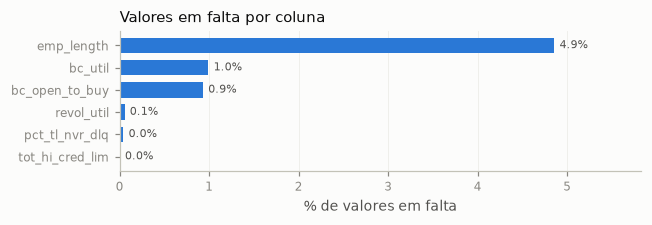

In [5]:
plotter.missing_bar(reg, REG_NUM + REG_CAT, filename="reg_missing.png");

In [6]:
# Outliers pelas barreiras de Tukey (1,5 x IQR) - só diagnóstico, nada é removido
reg_desc.outliers(REG_NUM + [REG_TARGET])


,limite_inf,limite_sup,n_abaixo,n_acima,%_fora
coluna,,,,,
loan_amnt,-9000.00,37400.00,0,0,0.00
annual_inc,-21250.00,156750.00,0,15621,4.22
dti,-5.55,40.77,0,0,0.00
fico_range_low,610.00,770.00,0,8862,2.39
revol_util,-11.00,125.80,0,22,0.01
revol_bal,-14434.00,41878.00,0,17661,4.77
open_acc,-1.00,23.00,0,9622,2.60
total_acc,-5.50,54.50,0,7508,2.03
inq_last_6mths,-1.50,2.50,0,26829,7.25


## A.2 Distribuições

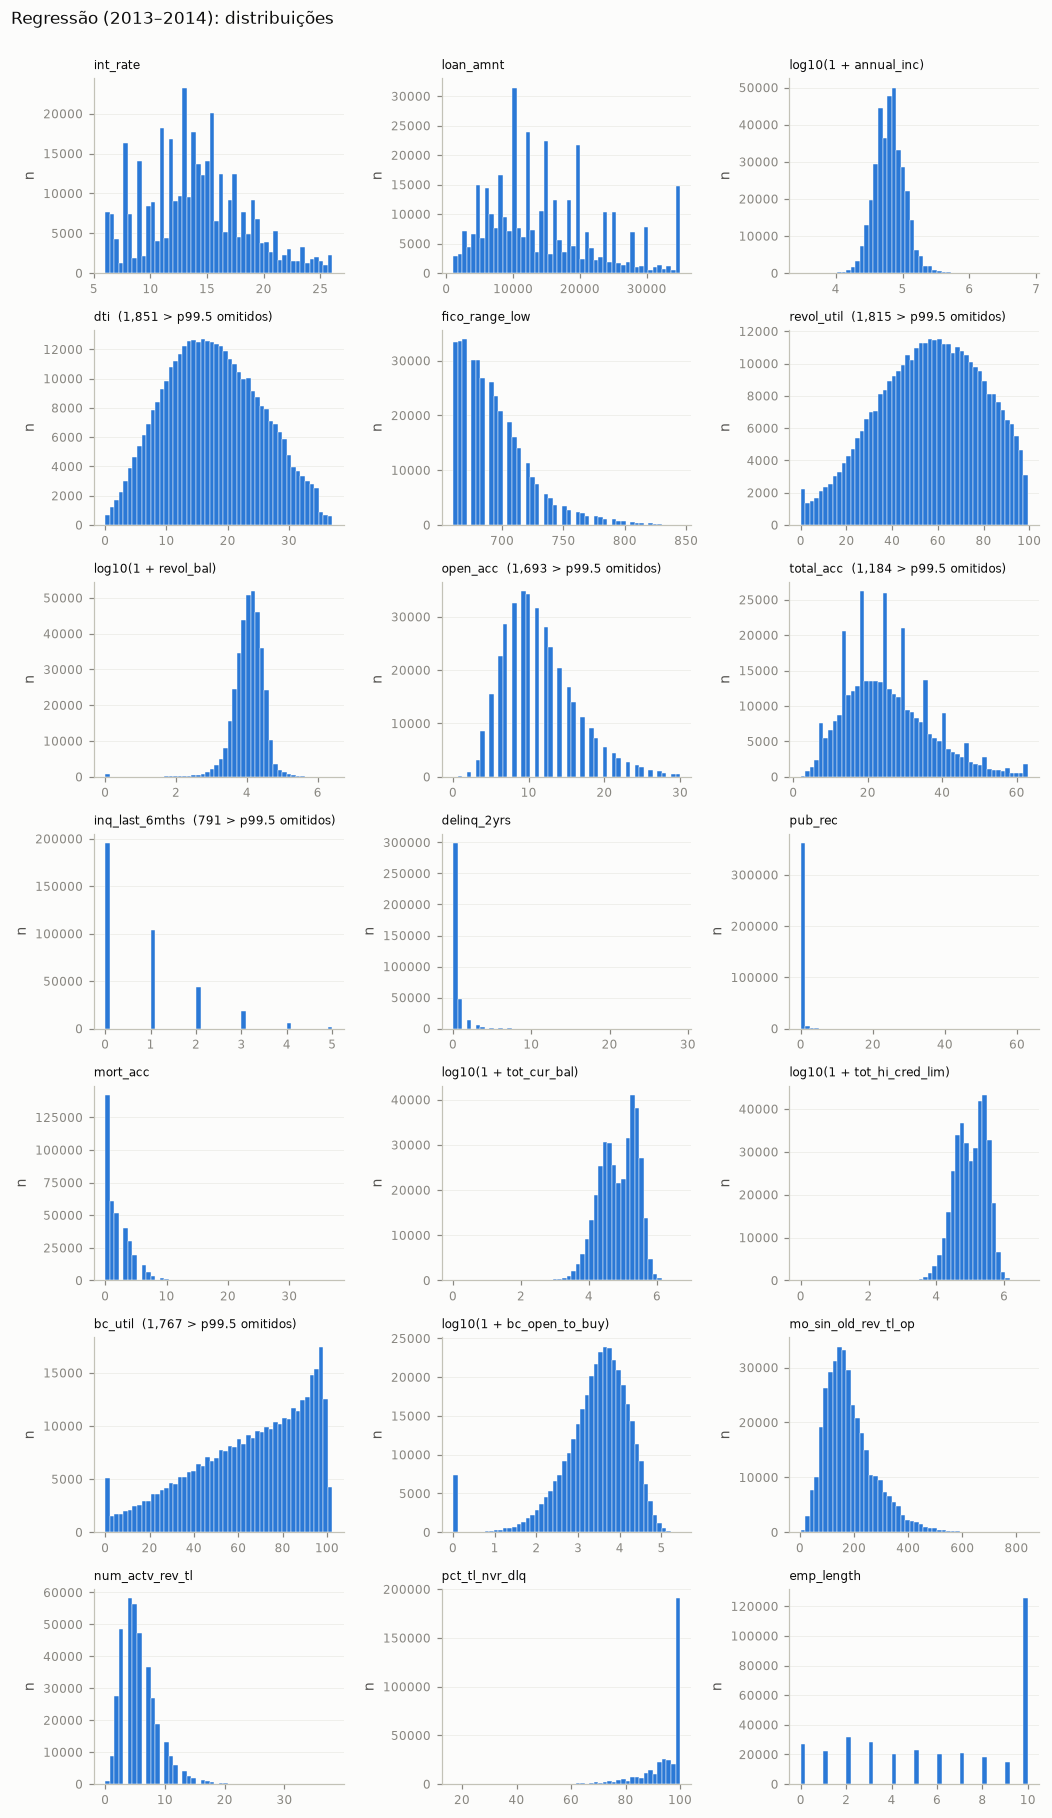

In [7]:
plotter.histograms(reg, [REG_TARGET] + REG_NUM, log_cols=REG_LOG, clip_cols=REG_CLIP,
                   title="Regressão (2013–2014): distribuições", filename="reg_histogramas.png");

## A.3 Relações com o alvo (`int_rate`)

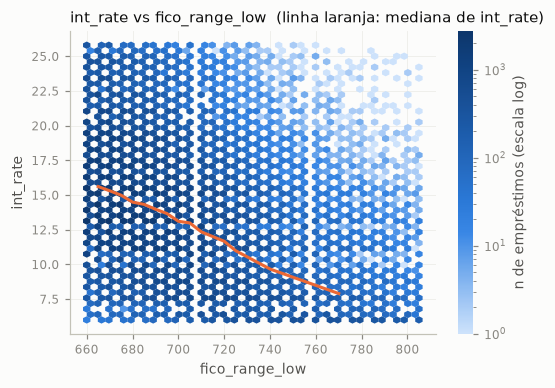

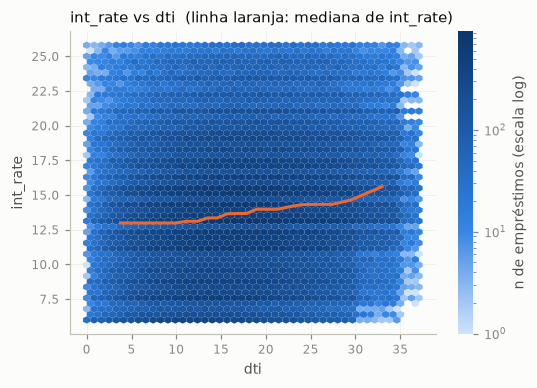

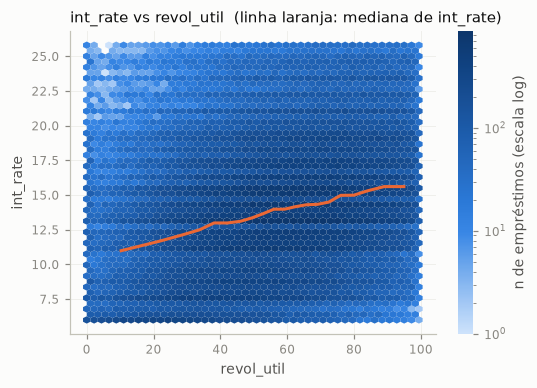

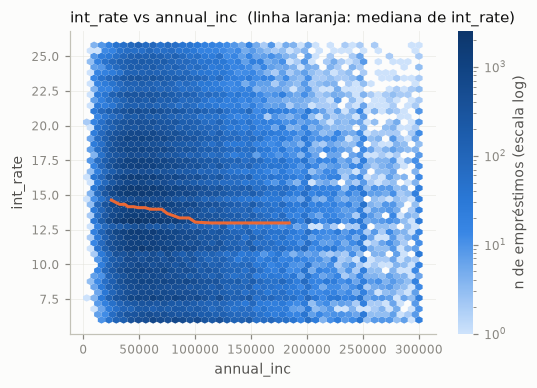

In [8]:
# Relação de int_rate com as variáveis de risco mais diretas (densidade + mediana)
for x in ["fico_range_low", "dti", "revol_util", "annual_inc"]:
    if x in reg.columns:
        plotter.hexbin(reg, x, REG_TARGET, filename=f"reg_{x}_vs_rate.png")


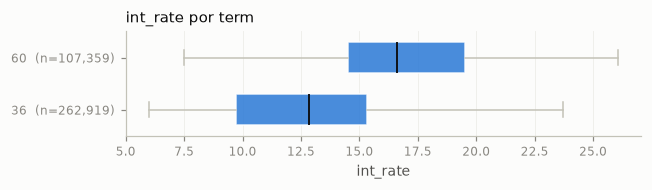

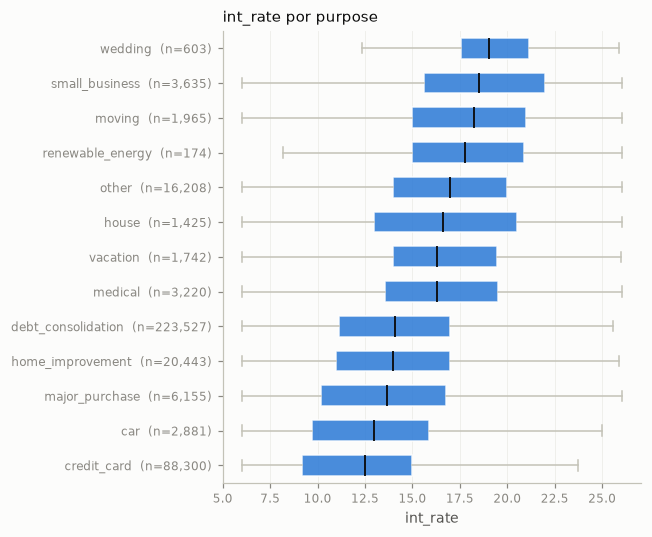

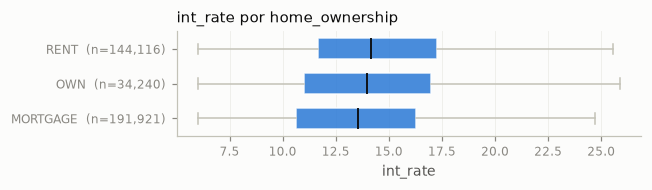

In [9]:
for cat in REG_CAT:
    plotter.box_by_category(reg, REG_TARGET, cat, filename=f"reg_rate_por_{cat}.png")


In [10]:
# Tabelas de apoio: int_rate médio por categoria (valores para citar no relatório)
for cat in REG_CAT:
    display(reg_desc.by_category(cat, REG_TARGET, min_count=100))


,n,%_total,media_int_rate
term,,,
60.0,107359,28.994,17.081
36.0,262919,71.006,12.811


,n,%_total,media_int_rate
purpose,,,
wedding,603,0.163,19.146
small_business,3635,0.982,18.525
moving,1965,0.531,18.101
renewable_energy,174,0.047,18.083
other,16208,4.377,17.086
house,1425,0.385,16.810
medical,3220,0.870,16.612
vacation,1742,0.470,16.553
debt_consolidation,223527,60.367,14.253


,n,%_total,media_int_rate
home_ownership,,,
RENT,144116,38.921,14.450
OWN,34240,9.247,14.192
MORTGAGE,191921,51.832,13.723


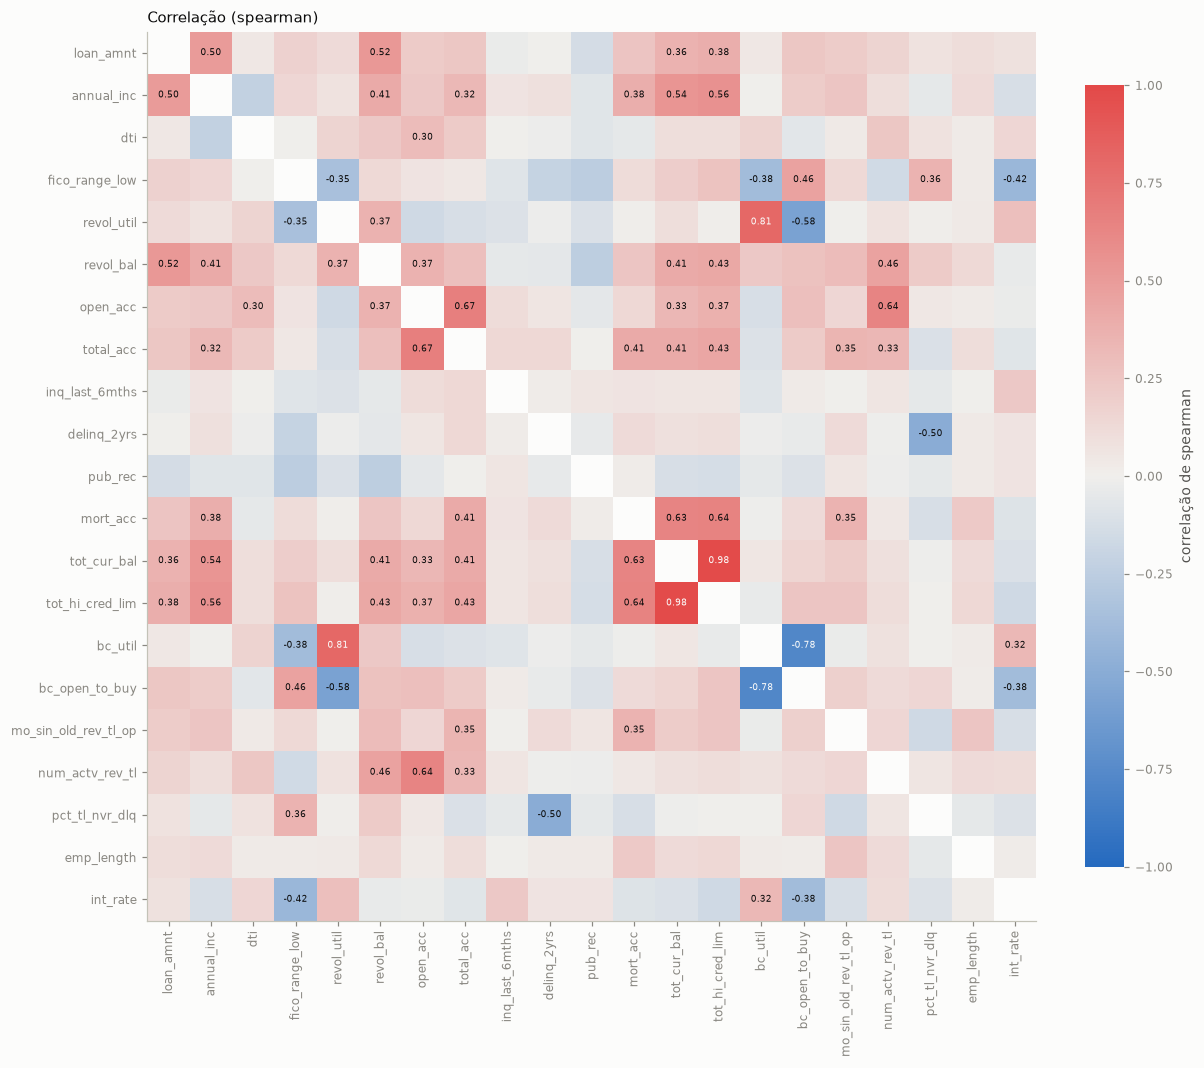

In [11]:
plotter.correlation_heatmap(reg, REG_NUM + [REG_TARGET], method="spearman",
                            filename="reg_correlacao.png");

## A.4 PCA e UMAP (regressão)

O pré-processamento (log -> imputação pela mediana -> padronização) e o PCA são **ajustados só nestes dados de desenvolvimento**, dentro de um `Pipeline`. O UMAP usa uma amostra reprodutível de 20 000 empréstimos (é lento). Os pontos são coloridos por `int_rate`: se as cores se organizarem no mapa, as variáveis contêm informação sobre a taxa.

Componentes para 80% da variância: 10


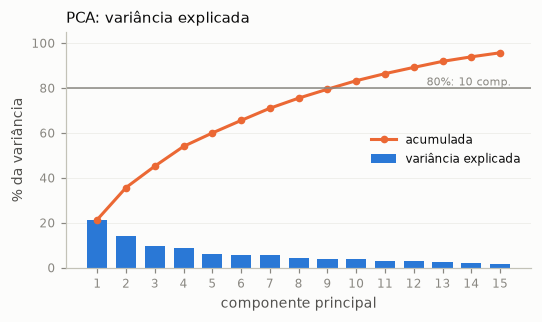

In [12]:
reg_dr = DimensionalityReducer(REG_NUM, log_cols=REG_LOG, sample_size=20_000).fit_pca(reg)
print("Componentes para 80% da variância:", reg_dr.n_components_for(0.8))
reg_dr.plot_scree(filename="reg_pca_scree.png");


In [13]:
# O que mede cada componente (pesos das variáveis)
reg_dr.loadings(n_components=3, top=10)


,PC1,PC2,PC3
bc_util,-0.027,0.547,-0.034
revol_util,0.004,0.531,-0.057
num_actv_rev_tl,0.205,0.125,0.446
bc_open_to_buy,0.173,-0.406,0.132
tot_hi_cred_lim,0.405,-0.005,-0.193
open_acc,0.302,-0.029,0.397
tot_cur_bal,0.385,0.064,-0.204
fico_range_low,0.115,-0.369,-0.006
dti,0.089,0.167,0.359
pct_tl_nvr_dlq,0.055,-0.048,0.335


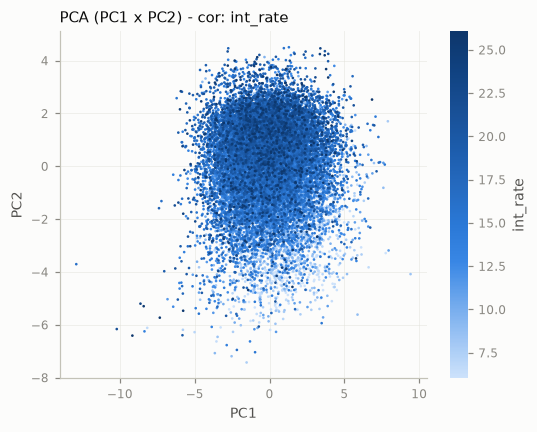

In [14]:
reg_sample = reg_dr.sampler.sample(reg, 20_000)
reg_dr.plot_embedding(reg_dr.pca_coordinates(reg_sample), reg_sample[REG_TARGET], kind="continuous",
                      label="int_rate", title="PCA (PC1 x PC2) - cor: int_rate",
                      xlabel="PC1", ylabel="PC2", filename="reg_pca_2d.png");


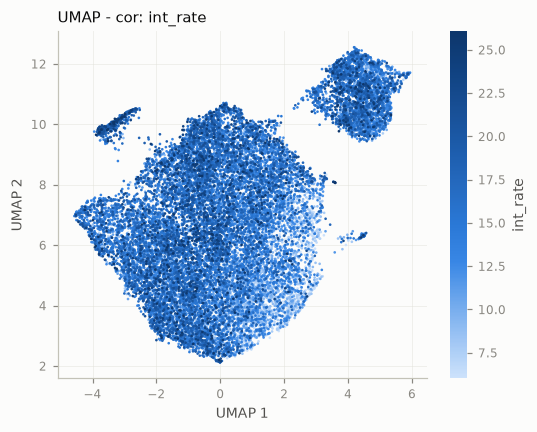

In [15]:
reg_umap_sample = reg_dr.fit_umap(reg)       # pode demorar 1–3 minutos
reg_dr.plot_embedding(reg_dr.umap_embedding, reg_umap_sample[REG_TARGET], kind="continuous",
                      label="int_rate", title="UMAP - cor: int_rate",
                      xlabel="UMAP 1", ylabel="UMAP 2", filename="reg_umap_2d.png");


---
# Parte B - Classificação (treino: 36 meses, 2007–2011)

## B.1 Distribuição das classes

São só dois números, por isso fica uma tabela e não um gráfico. A classe *At risk* tem 0 casos no treino (ver Fase 1).

In [16]:
class_table = (cls[config.CLASS_COL].value_counts()
               .reindex(config.CLASS_ORDER)
               .to_frame("n")
               .assign(pct=lambda t: (100 * t["n"] / t["n"].sum()).round(1)))
class_table


,n,pct
target,,
Good standing,27646,87.7
Default,3876,12.3


## B.2 Estatística descritiva e outliers

In [17]:
cls_desc = DescriptiveAnalysis(cls)
cls_desc.summary(CLS_NUM)


,count,missing_%,mean,std,min,1%,25%,50%,75%,99%,max,skew
loan_amnt,31522.0,0.00,9533.78,6314.53,500.00,1000.00,5000.00,8000.00,12000.00,28000.00,35000.00,1.18
annual_inc,31518.0,0.01,67495.95,64255.97,1896.00,13200.00,39996.00,56004.00,80000.00,240000.00,6000000.00,30.94
dti,31522.0,0.00,13.07,6.75,0.00,0.28,7.82,13.09,18.39,26.70,29.99,0.01
fico_range_low,31522.0,0.00,713.06,36.77,610.00,650.00,685.00,710.00,740.00,800.00,825.00,0.46
revol_util,31436.0,0.27,48.03,28.55,0.00,0.00,24.20,48.10,71.70,98.70,119.00,0.01
revol_bal,31522.0,0.00,13915.61,23509.09,0.00,0.00,3339.00,8191.00,16201.50,105544.08,1207359.00,11.84
open_acc,31493.0,0.09,9.22,4.51,1.00,2.00,6.00,8.00,12.00,23.00,47.00,1.09
total_acc,31493.0,0.09,21.47,11.52,1.00,4.00,13.00,20.00,28.00,56.00,90.00,0.87
inq_last_6mths,31493.0,0.09,1.09,1.60,0.00,0.00,0.00,1.00,2.00,7.00,33.00,3.73
delinq_2yrs,31493.0,0.09,0.15,0.51,0.00,0.00,0.00,0.00,0.00,2.00,13.00,5.59


In [18]:
cls_desc.outliers(CLS_NUM)

,limite_inf,limite_sup,n_abaixo,n_acima,%_fora
coluna,,,,,
loan_amnt,-5500.00,22500.00,0,1698,5.39
annual_inc,-20010.00,140006.00,0,1565,4.97
dti,-8.04,34.25,0,0,0.00
fico_range_low,602.50,822.50,0,2,0.01
revol_util,-47.05,142.95,0,0,0.00
revol_bal,-15954.75,35495.25,0,2267,7.19
open_acc,-3.00,21.00,0,467,1.48
total_acc,-9.50,50.50,0,642,2.04
inq_last_6mths,-3.00,5.00,0,641,2.04


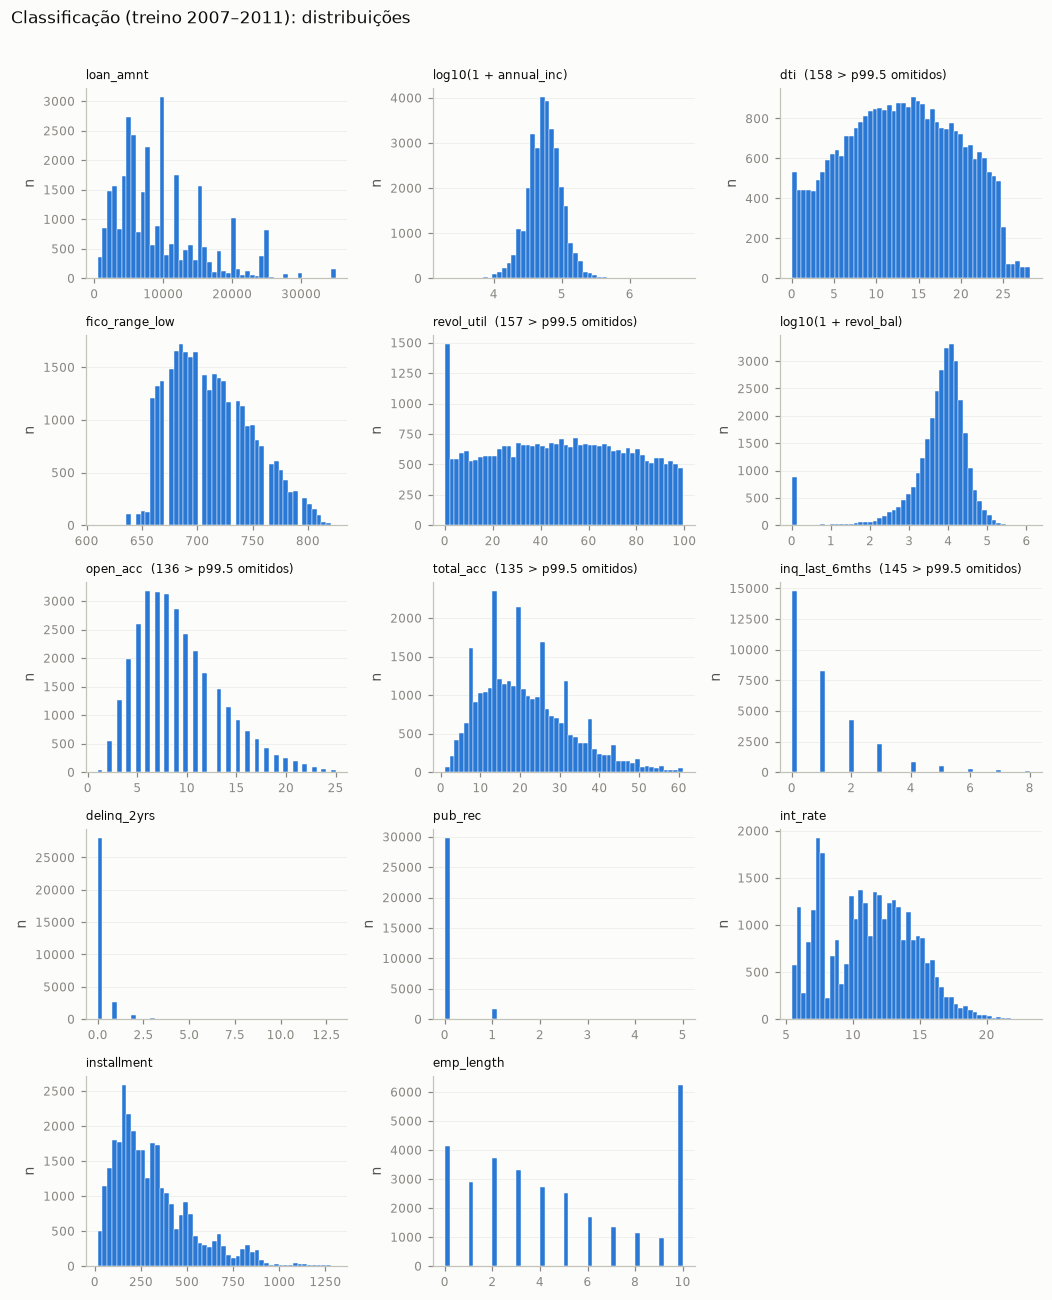

In [19]:
plotter.histograms(cls, CLS_NUM, log_cols=CLS_LOG, clip_cols=CLS_CLIP,
                   title="Classificação (treino 2007–2011): distribuições",
                   filename="cls_histogramas.png");

## B.3 Relações com o desfecho

Taxa de default por categoria e por decil, e distribuição de cada variável por classe (*raincloud*: forma + caixa + pontos).

,n,%_total,media_is_default
grade,,,
G,220,0.698,0.359
F,413,1.310,0.317
E,1299,4.121,0.227
D,3847,12.204,0.195
C,6339,20.110,0.155
B,9659,30.642,0.110
A,9745,30.915,0.059


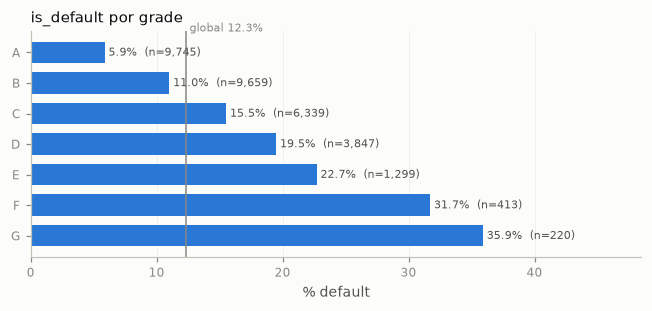

In [20]:
if "grade" in cls.columns:
    plotter.rate_by_category(cls, "grade", "is_default", order=GRADE_ORDER, xlabel="% default",
                             filename="cls_default_por_grade.png")
    display(cls_desc.by_category("grade", "is_default"))


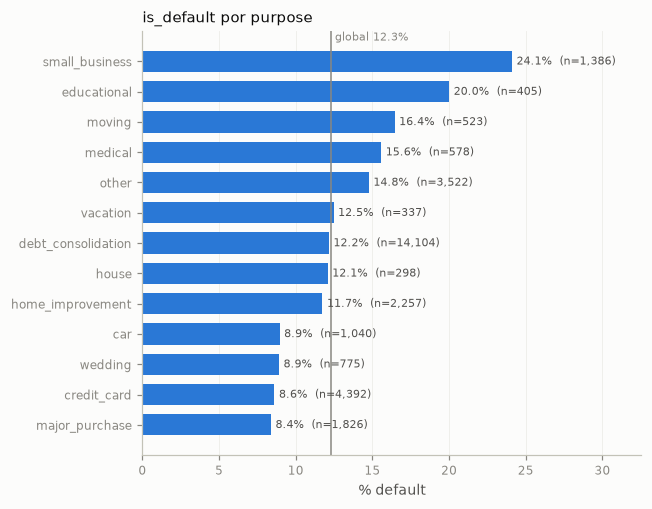

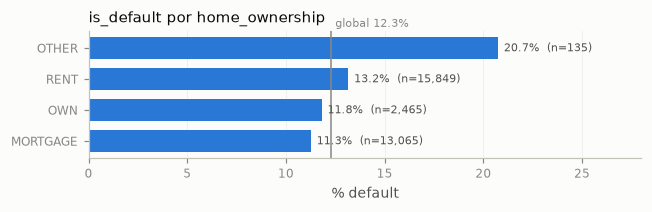

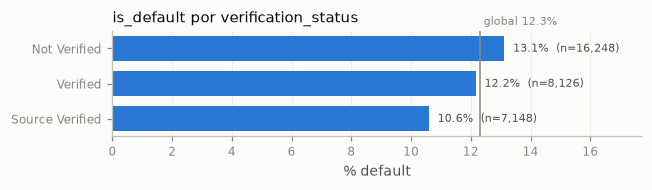

In [21]:
for cat in [c for c in CLS_CAT if c != "grade"]:
    plotter.rate_by_category(cls, cat, "is_default", xlabel="% default",
                             filename=f"cls_default_por_{cat}.png")


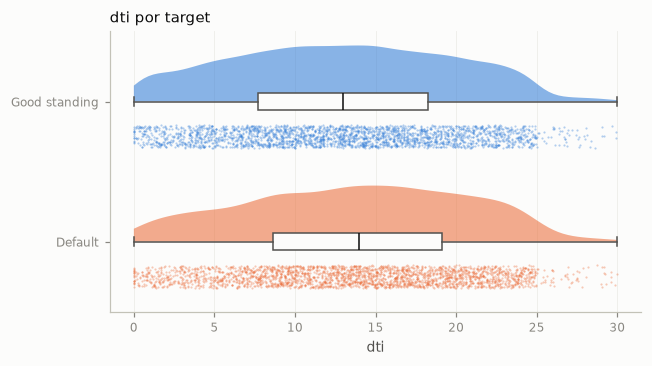

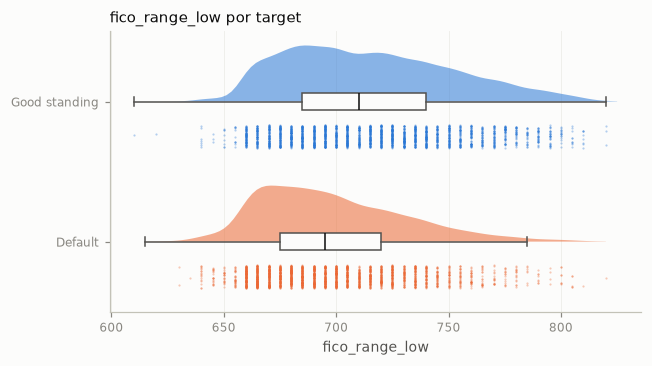

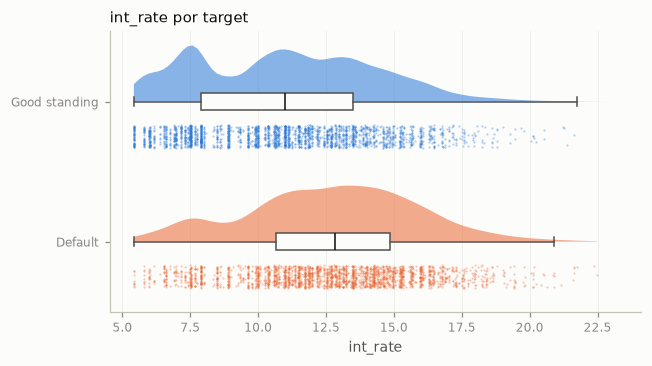

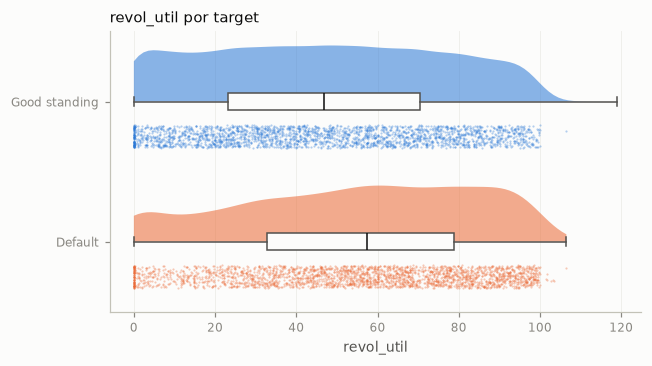

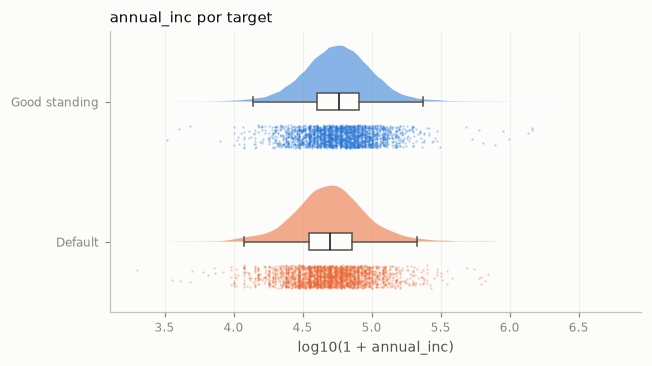

In [22]:
for col in ["dti", "fico_range_low", "int_rate", "revol_util", "annual_inc"]:
    if col in cls.columns:
        plotter.raincloud(cls, col, config.CLASS_COL, order=config.CLASS_ORDER,
                          log=col in CLS_LOG, filename=f"cls_raincloud_{col}.png")


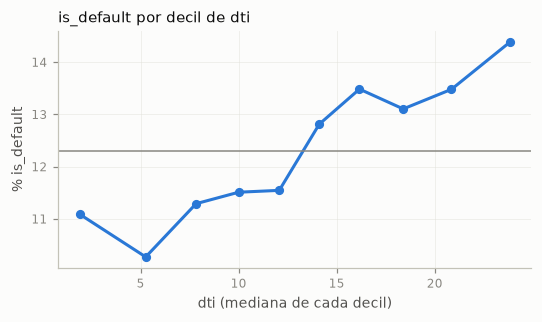

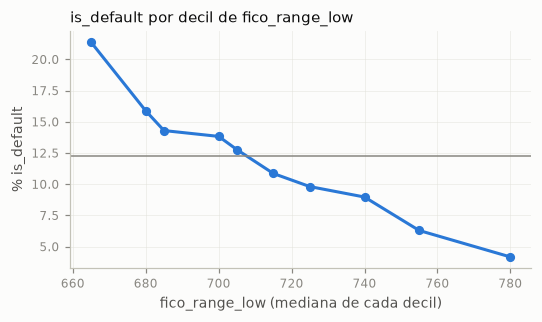

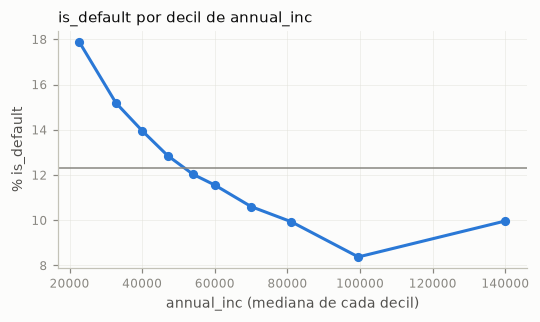

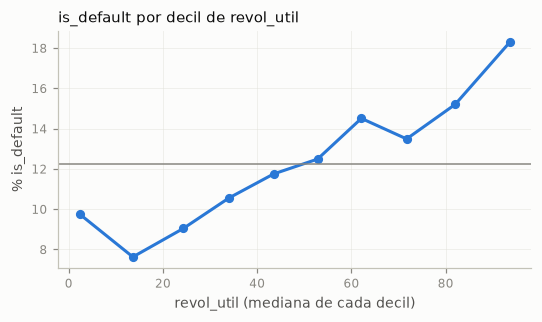

In [23]:
for col in ["dti", "fico_range_low", "annual_inc", "revol_util"]:
    if col in cls.columns:
        plotter.rate_by_bins(cls, col, "is_default", filename=f"cls_default_por_decil_{col}.png")


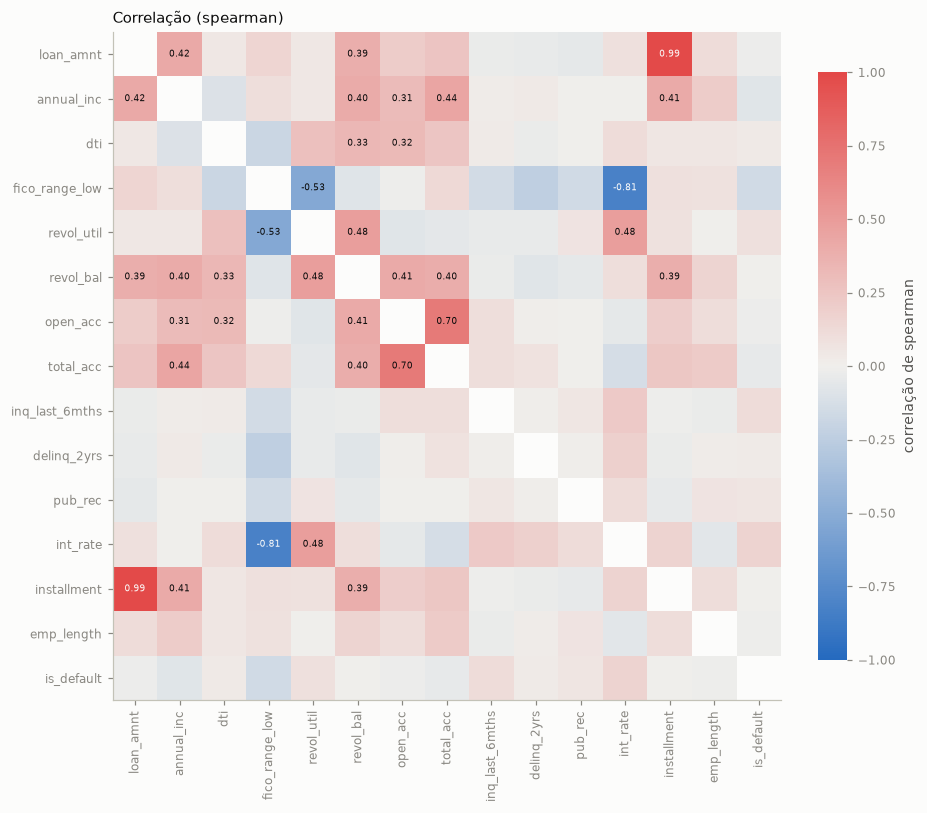

In [24]:
plotter.correlation_heatmap(cls, CLS_NUM + ["is_default"], method="spearman",
                            filename="cls_correlacao.png");

## B.4 PCA e UMAP (classificação)

Pontos coloridos pela classe, sempre com a mesma ordem de cores (`CLASS_ORDER`: Good standing azul, Default laranja). A amostra do UMAP é estratificada pela classe, para manter a proporção 87,7% / 12,3%.

Componentes para 80% da variância: 7


,PC1,PC2,PC3
fico_range_low,-0.056,0.577,-0.018
int_rate,0.140,-0.512,-0.194
revol_util,0.164,-0.462,-0.033
open_acc,0.345,0.086,0.456
installment,0.435,0.092,-0.449
loan_amnt,0.430,0.134,-0.440
total_acc,0.369,0.170,0.406
dti,0.182,-0.187,0.375
annual_inc,0.371,0.154,-0.089
revol_bal,0.351,-0.126,0.156


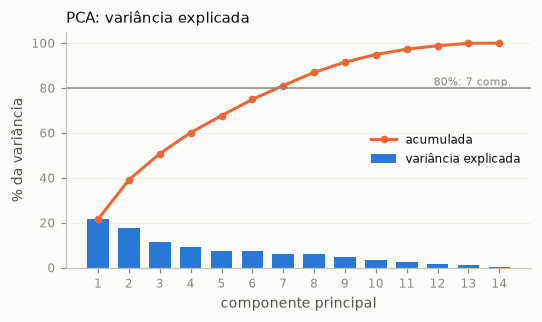

In [25]:
cls_dr = DimensionalityReducer(CLS_NUM, log_cols=CLS_LOG, sample_size=15_000).fit_pca(cls)
print("Componentes para 80% da variância:", cls_dr.n_components_for(0.8))
cls_dr.plot_scree(filename="cls_pca_scree.png")
cls_dr.loadings(n_components=3, top=10)


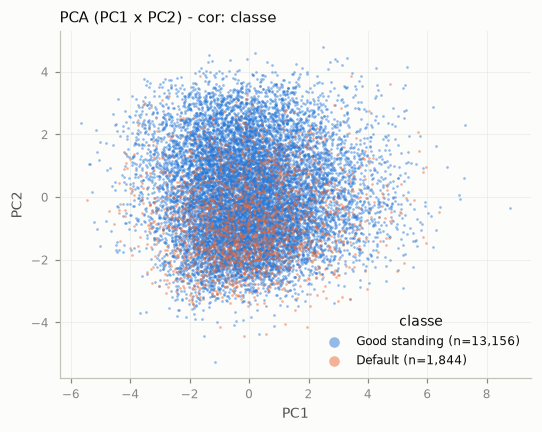

In [26]:
cls_sample = cls_dr.sampler.sample(cls, 15_000, stratify=config.CLASS_COL)
cls_dr.plot_embedding(cls_dr.pca_coordinates(cls_sample), cls_sample[config.CLASS_COL],
                      order=config.CLASS_ORDER, label="classe",
                      title="PCA (PC1 x PC2) - cor: classe", xlabel="PC1", ylabel="PC2",
                      filename="cls_pca_2d.png");


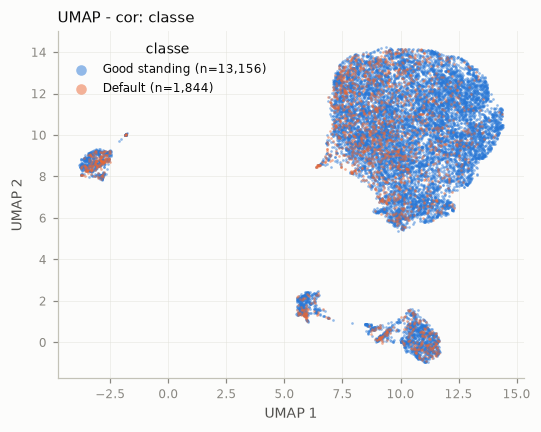

In [27]:
cls_umap_sample = cls_dr.fit_umap(cls, stratify=config.CLASS_COL)
cls_dr.plot_embedding(cls_dr.umap_embedding, cls_umap_sample[config.CLASS_COL],
                      order=config.CLASS_ORDER, label="classe", title="UMAP - cor: classe",
                      xlabel="UMAP 1", ylabel="UMAP 2", filename="cls_umap_2d.png");


---
# Parte C - Primeiros *insights* (para a secção 2b do relatório)

Preencher depois de correr o notebook com os dados reais. Para cada ponto: **o que se vê** (com número) -> **o que significa** -> **o que muda nas próximas fases**.

**Regressão**
1. Forma de `int_rate` (simétrica? multimodal por prazo?) -> …
2. Variáveis com relação mais forte com a taxa (hexbin, correlação) -> candidatas a features.
3. Diferenças por `term` e `purpose` -> …
4. Variáveis muito assimétricas / outliers -> transformação log e escalamento robusto no pipeline.
5. Pares muito correlacionados (ex: `revol_util` e `bc_util`) -> redundância; ter em conta na seleção de features.

**Classificação**
1. Desequilíbrio 87,7% / 12,3% -> métricas *macro*, balanceamento só nos folds de treino.
2. Taxa de default por `grade` (monotónica?) -> o `grade` é uma *baseline* forte (critério de sucesso).
3. `dti`, `fico`, `int_rate` por classe -> separação parcial ou forte?
4. Relações não lineares nos decis -> modelos não lineares (árvores, ensembles) podem ganhar.

**PCA vs UMAP**
1. Quantas componentes para 80% -> informação muito espalhada ou concentrada?
2. O que medem PC1 e PC2 (pesos) -> …
3. As classes / a taxa separam-se no mapa? Mais no UMAP do que no PCA? -> indica relações não lineares.
